In [ ]:
!pip install -q xgboost

import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    roc_auc_score
)
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")

In [ ]:
uploaded = files.upload()

filename = next(iter(uploaded))
data = pd.read_csv(io.BytesIO(uploaded[filename]))

print(data.shape)
display(data.head())

Saving skillcorner_enhanced_dataset(2).csv to skillcorner_enhanced_dataset(2).csv
(2955, 21)


,frames_sampled,ball_wide_share,ball_x_start,ball_progress_m,attack_width_mean,attack_depth_mean,attack_spacing_mean,defense_width_mean,defense_depth_mean,defense_spacing_mean,...,defenders_within_10m_mean,attackers_in_wide_zones_mean,attackers_ahead_of_ball_mean,tactic_label,match_id,phase_index,period,duration,match_minute,progress_speed_mps
0,6,0.333333,-2.58,-10.86,50.145,48.945,11.863295,33.620,51.498333,10.351788,...,0.833333,4.166667,6.833333,creation,1886347,0,1.0,6.1,0.016667,-1.780328
1,2,1.000000,-8.41,21.19,55.495,59.900,13.252009,33.645,49.975000,10.953125,...,2.500000,6.000000,4.000000,direct_attack,1886347,1,1.0,3.5,0.116667,6.054286
2,5,0.400000,-23.97,2.42,48.792,49.452,13.741458,33.466,52.192000,11.713284,...,0.400000,5.400000,8.600000,build_up,1886347,2,1.0,4.3,0.283333,0.562791
3,5,1.000000,-11.36,39.60,47.680,55.194,14.190966,39.762,51.806000,11.568380,...,1.200000,6.000000,3.400000,creation,1886347,3,1.0,5.1,0.366667,7.764706
4,5,1.000000,35.27,8.95,37.682,71.476,13.592233,31.426,50.768000,8.446606,...,2.800000,5.000000,1.600000,finishing,1886347,5,1.0,6.7,0.466667,1.335821


In [ ]:
sample_columns = [
    "ball_x_start",
    "ball_progress_m",
    "attack_width_mean",
    "attack_depth_mean",
    "duration",
    "progress_speed_mps",
    "tactic_label"
]

sample_data = data[sample_columns].head().round(2)

display(
    sample_data.style
    .hide(axis="index")
    .format(precision=2)
)

ball_x_start,ball_progress_m,attack_width_mean,attack_depth_mean,duration,progress_speed_mps,tactic_label
-2.58,-10.86,50.14,48.94,6.10,-1.78,creation
-8.41,21.19,55.50,59.90,3.50,6.05,direct_attack
-23.97,2.42,48.79,49.45,4.30,0.56,build_up
-11.36,39.60,47.68,55.19,5.10,7.76,creation
35.27,8.95,37.68,71.48,6.70,1.34,finishing


In [ ]:
original_features = [
    "frames_sampled",
    "ball_wide_share",
    "ball_x_start",
    "ball_progress_m",
    "attack_width_mean",
    "attack_depth_mean",
    "attack_spacing_mean",
    "defense_width_mean",
    "defense_depth_mean",
    "defense_spacing_mean",
    "defenders_within_5m_mean",
    "defenders_within_10m_mean",
    "attackers_in_wide_zones_mean",
    "attackers_ahead_of_ball_mean"
]

added_features = [
    "match_minute",
    "period",
    "duration",
    "progress_speed_mps"
]

features = original_features + added_features
target = "tactic_label"

test_matches = [2015213, 1899585]

train_data = data[
    ~data["match_id"].isin(test_matches)
].copy()

test_data = data[
    data["match_id"].isin(test_matches)
].copy()

X_train = train_data[features]
X_test = test_data[features]

y_train = train_data[target]
y_test = test_data[target]

label_encoder = LabelEncoder()
label_encoder.fit(data[target])

y_train_encoded = label_encoder.transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

training_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_encoded
)

print("Training phases:", len(train_data))
print("Testing phases:", len(test_data))
print("Features:", len(features))

Training phases: 2388
Testing phases: 567
Features: 18


In [ ]:
enhanced_xgboost = XGBClassifier(
    objective="multi:softprob",
    num_class=len(label_encoder.classes_),
    n_estimators=400,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

enhanced_xgboost.fit(
    X_train,
    y_train_encoded,
    sample_weight=training_weights
)

encoded_predictions = enhanced_xgboost.predict(X_test)

predictions = label_encoder.inverse_transform(
    encoded_predictions
)

predicted_probabilities = enhanced_xgboost.predict_proba(
    X_test
)

accuracy = accuracy_score(y_test, predictions)

macro_f1 = f1_score(
    y_test,
    predictions,
    average="macro"
)

print("Accuracy:", round(accuracy, 3))
print("Macro F1:", round(macro_f1, 3))

Accuracy: 0.919
Macro F1: 0.864


In [ ]:
print(
    classification_report(
        y_test,
        predictions,
        labels=label_encoder.classes_,
        zero_division=0
    )
)

                 precision    recall  f1-score   support

       build_up       0.97      1.00      0.98       117
       creation       0.95      0.90      0.92       233
  direct_attack       0.91      0.91      0.91        79
fast_transition       0.68      0.52      0.59        25
      finishing       0.87      0.96      0.91       113

       accuracy                           0.92       567
      macro avg       0.87      0.86      0.86       567
   weighted avg       0.92      0.92      0.92       567



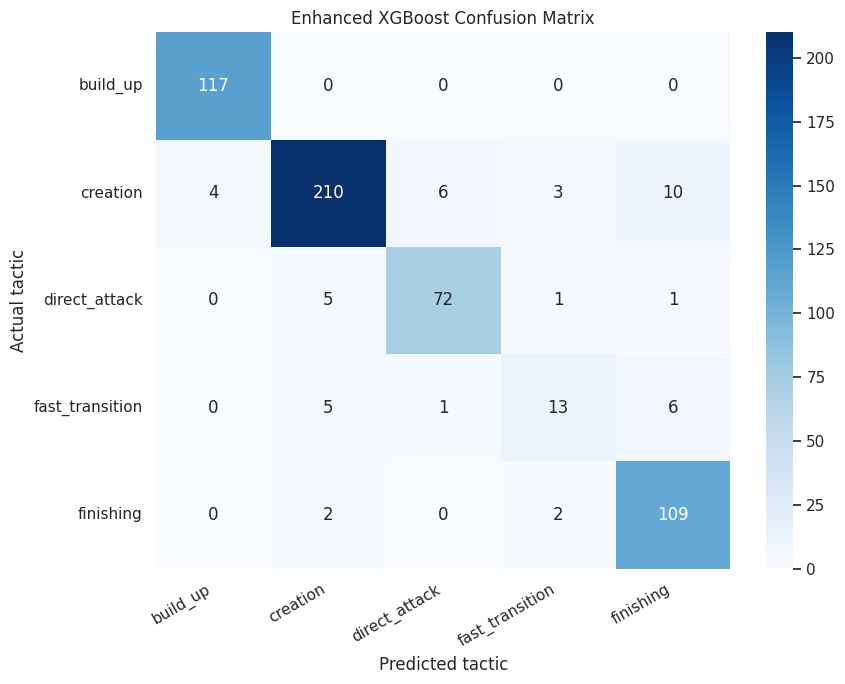

In [ ]:
matrix = confusion_matrix(
    y_test,
    predictions,
    labels=label_encoder.classes_
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Enhanced XGBoost Confusion Matrix")
plt.xlabel("Predicted tactic")
plt.ylabel("Actual tactic")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

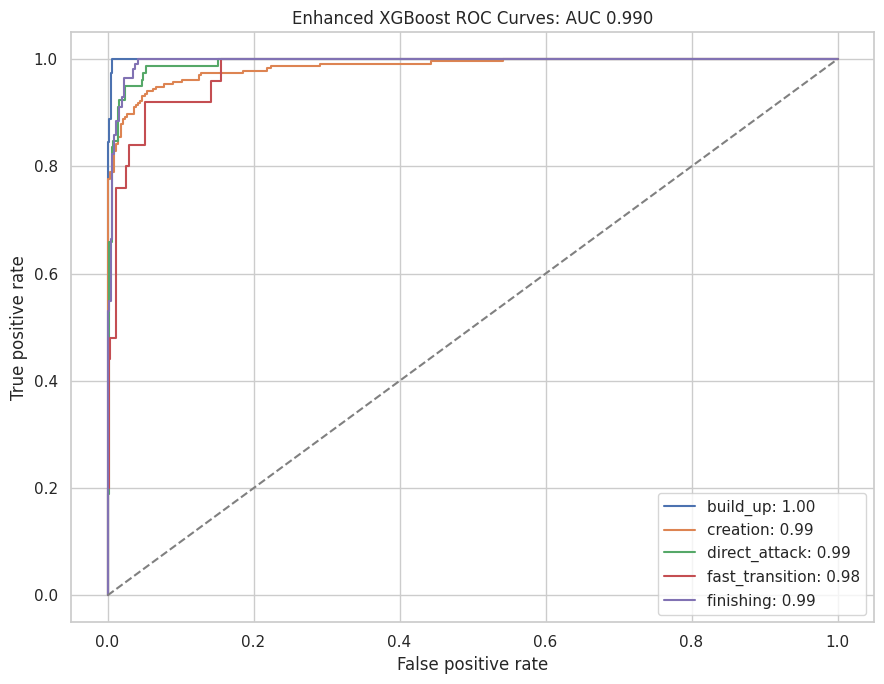

Macro AUC: 0.99


In [ ]:
class_names = label_encoder.classes_

y_test_binary = label_binarize(
    y_test_encoded,
    classes=np.arange(len(class_names))
)

plt.figure(figsize=(9, 7))

for class_index, class_name in enumerate(class_names):

    false_positive_rate, true_positive_rate, thresholds = roc_curve(
        y_test_binary[:, class_index],
        predicted_probabilities[:, class_index]
    )

    class_auc = auc(
        false_positive_rate,
        true_positive_rate
    )

    plt.plot(
        false_positive_rate,
        true_positive_rate,
        label=f"{class_name}: {class_auc:.2f}"
    )

macro_auc = roc_auc_score(
    y_test_binary,
    predicted_probabilities,
    average="macro",
    multi_class="ovr"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

plt.title(
    f"Enhanced XGBoost ROC Curves: AUC {macro_auc:.3f}"
)

plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend()
plt.tight_layout()
plt.show()

print("Macro AUC:", round(macro_auc, 3))

,Feature,Importance
2,ball_x_start,0.1961
0,frames_sampled,0.1187
3,ball_progress_m,0.1124
13,attackers_ahead_of_ball_mean,0.1018
5,attack_depth_mean,0.0849
4,attack_width_mean,0.0827
17,progress_speed_mps,0.0518
8,defense_depth_mean,0.0477
7,defense_width_mean,0.0359
9,defense_spacing_mean,0.0314


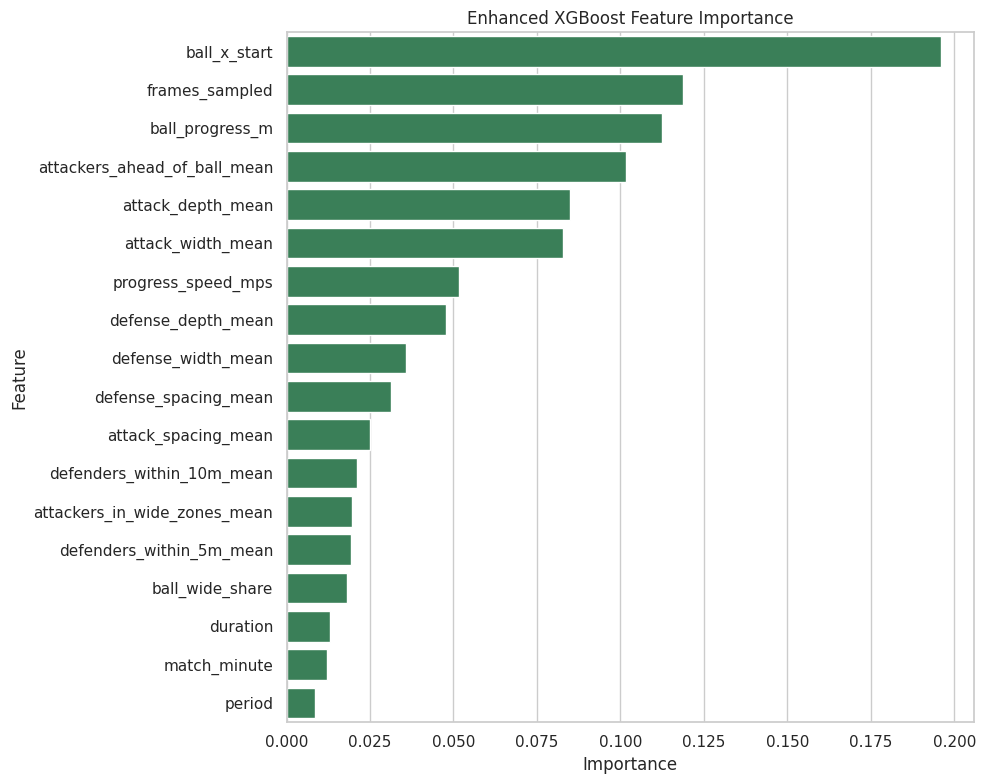

In [ ]:
importance_table = (
    pd.DataFrame({
        "Feature": features,
        "Importance": enhanced_xgboost.feature_importances_
    })
    .sort_values(
        "Importance",
        ascending=False
    )
)

display(importance_table.round(4))

plt.figure(figsize=(10, 8))

sns.barplot(
    data=importance_table,
    x="Importance",
    y="Feature",
    color="seagreen"
)

plt.title("Enhanced XGBoost Feature Importance")
plt.tight_layout()
plt.show()

,Model,Accuracy,Macro F1
1,Enhanced Random Forest,0.912,0.873
2,Original XGBoost,0.914,0.870
3,Enhanced XGBoost,0.919,0.864
0,Original Random Forest,0.912,0.863
4,SVC,0.879,0.825
5,MLP,0.858,0.790
6,KNN,0.756,0.649


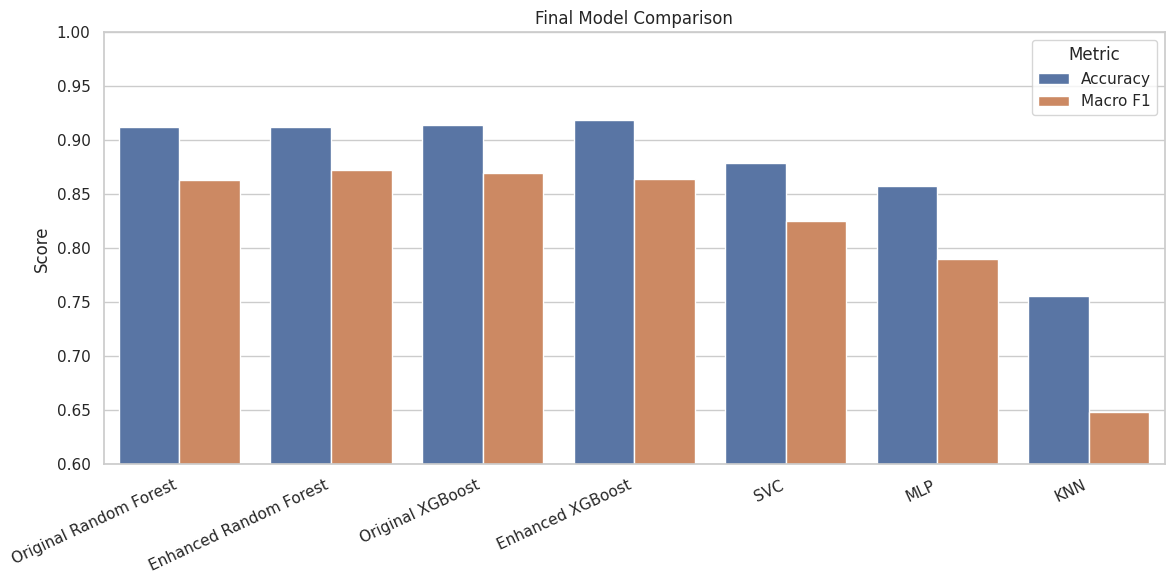

In [ ]:
model_results = pd.DataFrame({
    "Model": [
        "Original Random Forest",
        "Enhanced Random Forest",
        "Original XGBoost",
        "Enhanced XGBoost",
        "SVC",
        "MLP",
        "KNN"
    ],
    "Accuracy": [
        0.912,
        0.912,
        0.914,
        accuracy,
        0.879,
        0.858,
        0.756
    ],
    "Macro F1": [
        0.863,
        0.873,
        0.870,
        macro_f1,
        0.825,
        0.790,
        0.649
    ]
})

display(
    model_results.sort_values(
        "Macro F1",
        ascending=False
    ).round(3)
)

graph_data = model_results.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Macro F1"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=graph_data,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Final Model Comparison")
plt.xlabel("")
plt.ylabel("Score")
plt.ylim(0.60, 1.00)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

Rows: 2955
Columns: 21
Matches: 10
Missing values: 0
Duplicate rows: 0


,count
tactic_label,
creation,1226
finishing,662
build_up,598
direct_attack,337
fast_transition,132


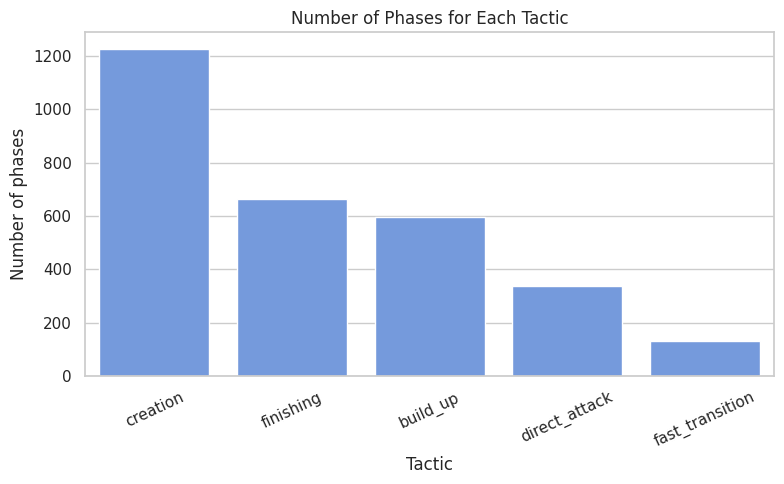

In [ ]:
print("Rows:", len(data))
print("Columns:", data.shape[1])
print("Matches:", data["match_id"].nunique())
print("Missing values:", data.isnull().sum().sum())
print("Duplicate rows:", data.duplicated().sum())

label_counts = data["tactic_label"].value_counts()

display(label_counts)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=label_counts.index,
    y=label_counts.values,
    color="cornflowerblue"
)

plt.title("Number of Phases for Each Tactic")
plt.xlabel("Tactic")
plt.ylabel("Number of phases")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC

comparison_models = {
    "Dummy baseline": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        )
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        class_weight="balanced",
        random_state=42
    ),

    "Enhanced Random Forest": RandomForestClassifier(
        n_estimators=400,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(
            n_neighbors=9,
            weights="distance"
        )
    ),

    "MLP": make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=(64, 32),
            max_iter=500,
            random_state=42
        )
    ),

    "SVC": make_pipeline(
        StandardScaler(),
        SVC(
            C=3,
            class_weight="balanced",
            random_state=42
        )
    )
}

comparison_results = []

for model_name, model in comparison_models.items():

    model.fit(
        X_train,
        y_train_encoded
    )

    model_predictions = model.predict(X_test)

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(
            y_test_encoded,
            model_predictions
        ),
        "Macro F1": f1_score(
            y_test_encoded,
            model_predictions,
            average="macro"
        )
    })

comparison_results.append({
    "Model": "Enhanced XGBoost",
    "Accuracy": accuracy,
    "Macro F1": macro_f1
})

all_model_results = (
    pd.DataFrame(comparison_results)
    .sort_values("Macro F1", ascending=False)
    .reset_index(drop=True)
)

display(all_model_results.round(3))

,Model,Accuracy,Macro F1
0,Enhanced XGBoost,0.919,0.864
1,Enhanced Random Forest,0.914,0.862
2,SVC,0.889,0.843
3,Logistic Regression,0.871,0.827
4,MLP,0.875,0.813
5,Decision Tree,0.847,0.790
6,KNN,0.810,0.718
7,Dummy baseline,0.411,0.116


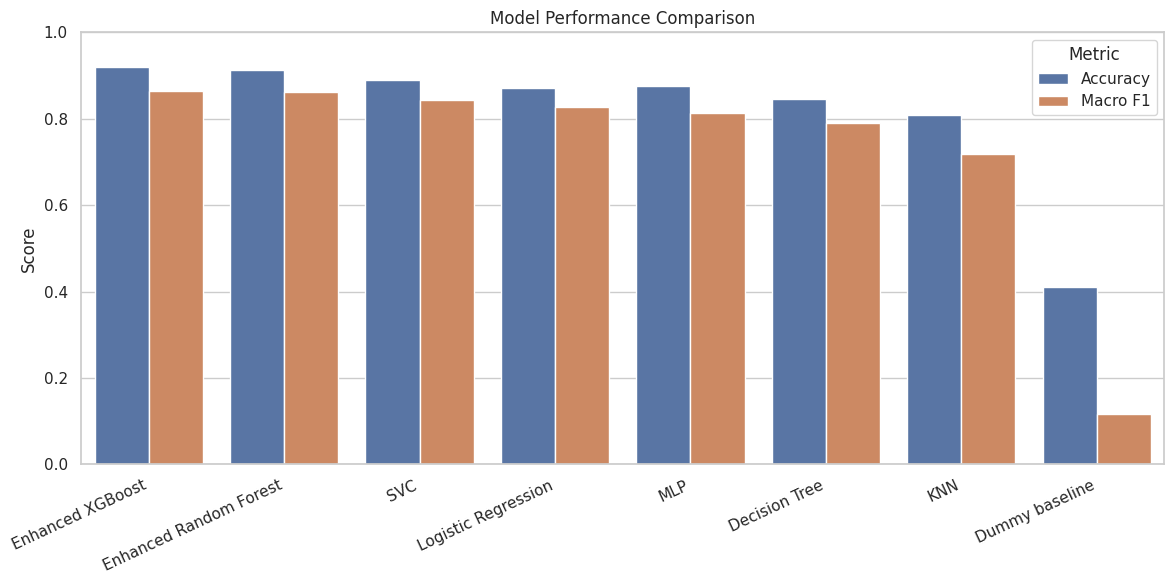

In [ ]:
comparison_graph = all_model_results.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Macro F1"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_graph,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Model Performance Comparison")
plt.xlabel("")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

,Feature,Importance,Variation
2,ball_x_start,0.3412,0.0169
3,ball_progress_m,0.2175,0.0315
0,frames_sampled,0.1451,0.0249
4,attack_width_mean,0.0342,0.0198
13,attackers_ahead_of_ball_mean,0.0282,0.0107
5,attack_depth_mean,0.0236,0.0077
17,progress_speed_mps,0.0205,0.0078
7,defense_width_mean,0.0099,0.0097
8,defense_depth_mean,0.0095,0.0064
15,period,0.0000,0.0000


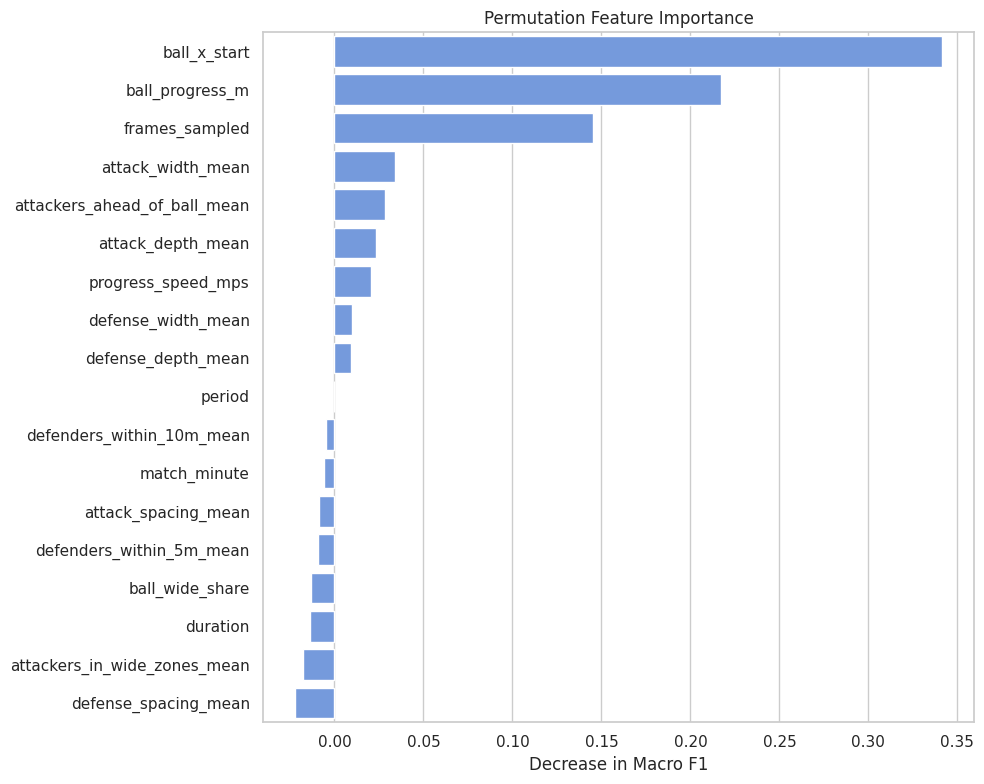

In [ ]:
from sklearn.inspection import permutation_importance

permutation_results = permutation_importance(
    enhanced_xgboost,
    X_test,
    y_test_encoded,
    scoring="f1_macro",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

permutation_table = (
    pd.DataFrame({
        "Feature": features,
        "Importance": permutation_results.importances_mean,
        "Variation": permutation_results.importances_std
    })
    .sort_values("Importance", ascending=False)
)

display(permutation_table.round(4))

plt.figure(figsize=(10, 8))

sns.barplot(
    data=permutation_table,
    x="Importance",
    y="Feature",
    color="cornflowerblue"
)

plt.title("Permutation Feature Importance")
plt.xlabel("Decrease in Macro F1")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [ ]:
feature_sets = {
    "All features": original_features,

    "Remove 2": [
        feature for feature in original_features
        if feature not in [
            "ball_wide_share",
            "attackers_in_wide_zones_mean"
        ]
    ],

    "Remove 3": [
        feature for feature in original_features
        if feature not in [
            "ball_wide_share",
            "attackers_in_wide_zones_mean",
            "attack_spacing_mean"
        ]
    ],

    "Remove 5": [
        feature for feature in original_features
        if feature not in [
            "ball_wide_share",
            "attackers_in_wide_zones_mean",
            "attack_spacing_mean",
            "defense_spacing_mean",
            "defenders_within_5m_mean"
        ]
    ]
}

feature_test_results = []

for test_name, selected_features in feature_sets.items():

    feature_model = RandomForestClassifier(
        n_estimators=400,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    feature_model.fit(
        train_data[selected_features],
        y_train
    )

    feature_predictions = feature_model.predict(
        test_data[selected_features]
    )

    feature_test_results.append({
        "Feature Set": test_name,
        "Features Kept": len(selected_features),
        "Accuracy": accuracy_score(
            y_test,
            feature_predictions
        ),
        "Macro F1": f1_score(
            y_test,
            feature_predictions,
            average="macro"
        )
    })

feature_test_results = pd.DataFrame(
    feature_test_results
)

display(feature_test_results.round(3))

,Feature Set,Features Kept,Accuracy,Macro F1
0,All features,14,0.908,0.855
1,Remove 2,12,0.910,0.857
2,Remove 3,11,0.915,0.864
3,Remove 5,9,0.910,0.857


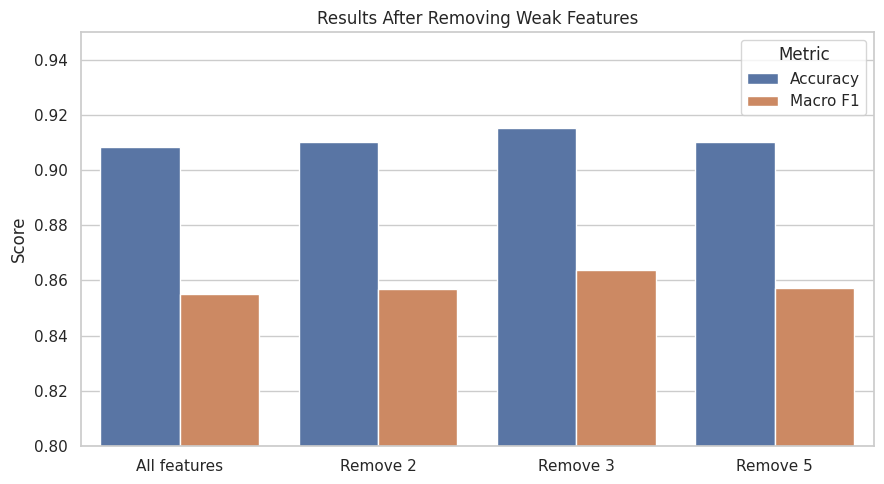

In [ ]:
feature_graph = feature_test_results.melt(
    id_vars=["Feature Set", "Features Kept"],
    value_vars=["Accuracy", "Macro F1"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_graph,
    x="Feature Set",
    y="Score",
    hue="Metric"
)

plt.title("Results After Removing Weak Features")
plt.xlabel("")
plt.ylabel("Score")
plt.ylim(0.80, 0.95)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import GroupKFold

group_kfold = GroupKFold(
    n_splits=5
)

group_results = []

for fold_number, (fold_train, fold_test) in enumerate(
    group_kfold.split(
        data[features],
        data[target],
        groups=data["match_id"]
    ),
    start=1
):

    fold_model = RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    fold_model.fit(
        data.iloc[fold_train][features],
        data.iloc[fold_train][target]
    )

    fold_predictions = fold_model.predict(
        data.iloc[fold_test][features]
    )

    group_results.append({
        "Fold": fold_number,
        "Accuracy": accuracy_score(
            data.iloc[fold_test][target],
            fold_predictions
        ),
        "Macro F1": f1_score(
            data.iloc[fold_test][target],
            fold_predictions,
            average="macro"
        )
    })

group_results = pd.DataFrame(group_results)

display(group_results.round(3))

print(
    "Average accuracy:",
    round(group_results["Accuracy"].mean(), 3)
)

print(
    "Average macro F1:",
    round(group_results["Macro F1"].mean(), 3)
)

print(
    "Macro F1 variation:",
    round(group_results["Macro F1"].std(), 3)
)

,Fold,Accuracy,Macro F1
0,1,0.899,0.845
1,2,0.899,0.852
2,3,0.932,0.867
3,4,0.915,0.828
4,5,0.878,0.790


Average accuracy: 0.905
Average macro F1: 0.836
Macro F1 variation: 0.029


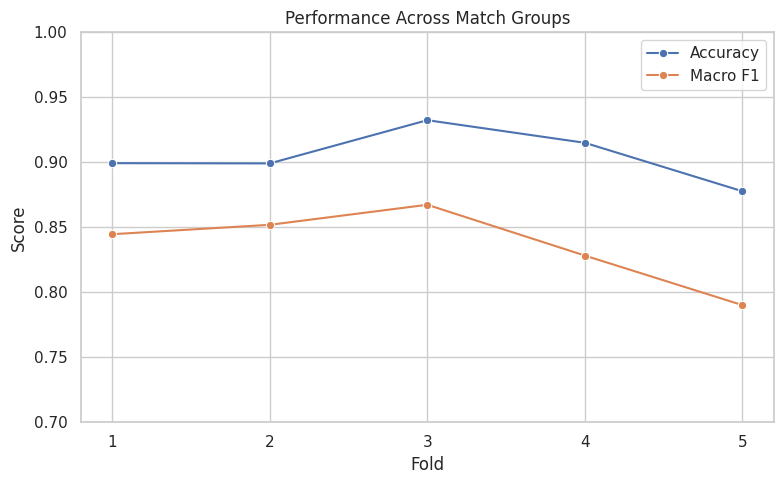

In [ ]:
plt.figure(figsize=(8, 5))

sns.lineplot(
    data=group_results,
    x="Fold",
    y="Accuracy",
    marker="o",
    label="Accuracy"
)

sns.lineplot(
    data=group_results,
    x="Fold",
    y="Macro F1",
    marker="o",
    label="Macro F1"
)

plt.title("Performance Across Match Groups")
plt.ylabel("Score")
plt.ylim(0.70, 1.00)
plt.xticks(group_results["Fold"])
plt.tight_layout()
plt.show()

In [ ]:
best_settings = pd.DataFrame({
    "Setting": [
        "Number of trees",
        "Maximum depth",
        "Learning rate",
        "Subsample",
        "Column sample",
        "Minimum child weight",
        "Regularization"
    ],
    "Best Value": [
        400,
        7,
        0.03,
        0.8,
        0.8,
        5,
        1
    ]
})

display(best_settings)

print("Combinations tested: 25")
print("Folds per combination: 5")
print("Total model fits: 125")
print("Best validation macro F1: 0.884")

,Setting,Best Value
0,Number of trees,400.00
1,Maximum depth,7.00
2,Learning rate,0.03
3,Subsample,0.80
4,Column sample,0.80
5,Minimum child weight,5.00
6,Regularization,1.00


Combinations tested: 25
Folds per combination: 5
Total model fits: 125
Best validation macro F1: 0.884


In [ ]:
prediction_review = test_data[
    ["match_id", "phase_index", "tactic_label"]
].copy()

prediction_review["predicted_tactic"] = predictions

prediction_review["confidence"] = (
    predicted_probabilities.max(axis=1)
)

prediction_review["correct"] = (
    prediction_review["tactic_label"]
    == prediction_review["predicted_tactic"]
)

print("Correct predictions:")
display(
    prediction_review[
        prediction_review["correct"]
    ].head(10)
)

print("Incorrect predictions:")
display(
    prediction_review[
        ~prediction_review["correct"]
    ]
    .sort_values(
        "confidence",
        ascending=False
    )
    .head(15)
)

Correct predictions:


,match_id,phase_index,tactic_label,predicted_tactic,confidence,correct
307,1899585,0,creation,creation,0.998928,True
308,1899585,1,build_up,build_up,0.999797,True
309,1899585,7,creation,creation,0.997796,True
310,1899585,8,build_up,build_up,0.992982,True
311,1899585,9,creation,creation,0.998463,True
312,1899585,10,finishing,finishing,0.999496,True
313,1899585,11,creation,creation,0.990797,True
314,1899585,12,finishing,finishing,0.999939,True
315,1899585,13,finishing,finishing,0.955244,True
316,1899585,15,direct_attack,direct_attack,0.905653,True


Incorrect predictions:


,match_id,phase_index,tactic_label,predicted_tactic,confidence,correct
357,1899585,96,creation,direct_attack,0.997907,False
335,1899585,51,creation,build_up,0.991035,False
572,1899585,431,creation,finishing,0.989872,False
428,1899585,198,fast_transition,finishing,0.988557,False
338,1899585,56,creation,build_up,0.983345,False
2539,2015213,217,creation,finishing,0.978963,False
2646,2015213,382,direct_attack,fast_transition,0.977135,False
433,1899585,205,creation,finishing,0.952021,False
402,1899585,164,creation,direct_attack,0.946427,False
2410,2015213,7,creation,direct_attack,0.945914,False


In [ ]:
print("FINAL PROJECT RESULTS")
print()
print("Dataset phases:", len(data))
print("Matches:", data["match_id"].nunique())
print("Features:", len(features))
print("Training phases:", len(train_data))
print("Testing phases:", len(test_data))
print()
print("Enhanced XGBoost accuracy:", round(accuracy, 3))
print("Enhanced XGBoost macro F1:", round(macro_f1, 3))
print("Macro AUC:", round(macro_auc, 3))
print()
print("Hardest tactic: fast_transition")
print("Most important feature:", importance_table.iloc[0]["Feature"])
print("Best tuning validation macro F1: 0.884")

FINAL PROJECT RESULTS

Dataset phases: 2955
Matches: 10
Features: 18
Training phases: 2388
Testing phases: 567

Enhanced XGBoost accuracy: 0.919
Enhanced XGBoost macro F1: 0.864
Macro AUC: 0.99

Hardest tactic: fast_transition
Most important feature: ball_x_start
Best tuning validation macro F1: 0.884


,Model,Accuracy,Macro F1
0,Enhanced XGBoost,0.919,0.864
1,Original XGBoost,0.914,0.870
2,Original Random Forest,0.912,0.863
3,Enhanced Random Forest,0.912,0.873
4,SVC,0.879,0.825
5,Logistic Regression,0.863,0.811
6,MLP,0.858,0.790
7,Decision Tree,0.814,0.761
8,KNN,0.756,0.649
9,Dummy Baseline,0.409,0.116


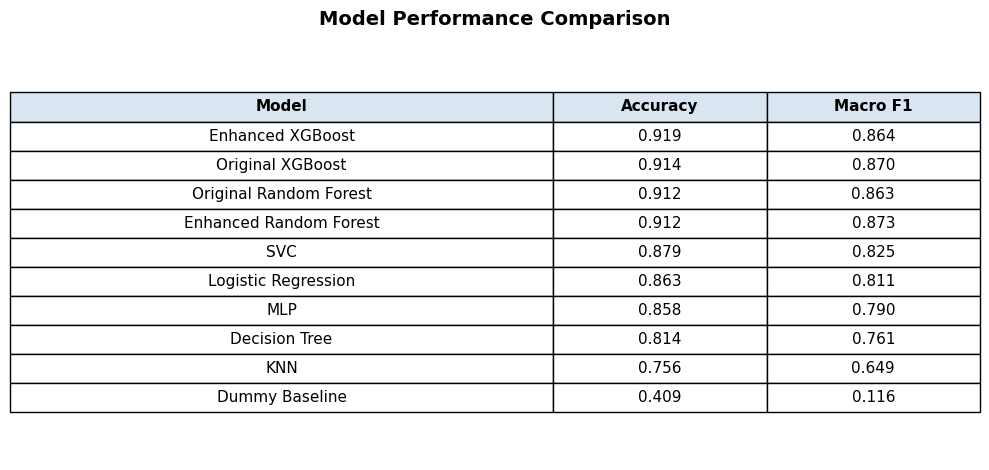

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

model_results = pd.DataFrame({
    "Model": [
        "Dummy Baseline",
        "KNN",
        "Decision Tree",
        "MLP",
        "Logistic Regression",
        "SVC",
        "Original Random Forest",
        "Enhanced Random Forest",
        "Original XGBoost",
        "Enhanced XGBoost"
    ],
    "Accuracy": [
        0.409,
        0.756,
        0.814,
        0.858,
        0.863,
        0.879,
        0.912,
        0.912,
        0.914,
        0.919
    ],
    "Macro F1": [
        0.116,
        0.649,
        0.761,
        0.790,
        0.811,
        0.825,
        0.863,
        0.873,
        0.870,
        0.864
    ]
})

model_results = model_results.sort_values(
    "Accuracy",
    ascending=False
).reset_index(drop=True)

display(model_results.style.format({
    "Accuracy": "{:.3f}",
    "Macro F1": "{:.3f}"
}))

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.axis("off")

table = ax.table(
    cellText=[
        [row["Model"], f'{row["Accuracy"]:.3f}', f'{row["Macro F1"]:.3f}']
        for _, row in model_results.iterrows()
    ],
    colLabels=["Model", "Accuracy", "Macro F1"],
    cellLoc="center",
    colLoc="center",
    loc="center",
    colWidths=[0.56, 0.22, 0.22]
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.55)

for column in range(3):
    table[(0, column)].set_text_props(weight="bold")
    table[(0, column)].set_facecolor("#d9e6f2")

plt.title("Model Performance Comparison", fontsize=14, weight="bold", pad=14)
plt.tight_layout()
plt.savefig("model_results_table.png", dpi=300, bbox_inches="tight")
plt.show()